# Transformación evolutiva de atributos: forma, relevancia, reducción y síntesis

**Práctica final — IA con inspiración biológica** · Máster en Ciencia y Tecnología, UC3M · Andrea López Salazar

Aprendemos con **CMA-ES**, viendo solo el entrenamiento, una transformación $X \to X'$ con **menos atributos que $X$** ($\dim X' < n$, como exige el enunciado) en cuatro bloques:

1. **Forma**: un exponente de Yeo-Johnson $\lambda_j \in [-2, 2]$ por atributo.
2. **Relevancia**: estandarizar y ponderar con $w_j \in [0, 3]$.
3. **Reducción**: se eliminan los atributos con $w_j < \tau$. **El umbral $\tau$ lo aprende CMA-ES** junto con los pesos.
4. **Síntesis**: el hueco que deja la reducción se rellena (en la fracción $\rho$ que también aprende CMA-ES) con componentes principales del espacio aprendido, sin pasar nunca de $n-1$ atributos.

**Resultados** (12 datasets × 5 particiones nunca usadas para diseñar el método): $X'$ usa de media el **83 %** de los atributos y **siempre menos de $n$**. El error baja de forma concluyente en **KNN (−24,3 %, 12/12 datasets, $p=0{,}004$)** y, sin significación, en **regresión lineal (−4,4 %)**; en los **árboles queda igual** (+0,1 %, Random Forest +0,5 %). Frente a la versión anterior sin reducir ($2n$ atributos), reducir cuesta poco salvo en Random Forest (+2,8 %), que pierde las direcciones oblicuas que le daba la síntesis: **con $\dim X'<n$, reducir y sintetizar compiten**. Entre las transformaciones que no aumentan la dimensión, $P$ tiene el mejor rango medio.

Este notebook contiene **todo el proceso** y se puede ejecutar de principio a fin en otro ordenador (ver la sección 0).

## 0. Cómo ejecutarlo

**Instalación** (una vez, desde la carpeta `PTCA-FINAL/`):

```bash
python -m venv .venv && source .venv/bin/activate      # en Windows: .venv\Scripts\activate
pip install -r requirements.txt
jupyter lab final/notebook_final.ipynb
```

- La **primera vez** hace falta internet: diez de los doce datasets se descargan de OpenML y se guardan en `~/scikit_learn_data` (después funciona sin conexión). Los dos de la práctica están en `DATASETS/`.
- Por defecto el notebook **no repite los experimentos**: lee los CSV ya guardados en `final/resultados/` y `reduccion/resultados/` y rehace todo el análisis, las figuras y las tablas en unos segundos. Para repetir un experimento, pon su entrada de `RECALCULAR` a `True` (el CSV anterior se guarda como `.bak`).
- `N_JOBS` fija cuántos procesos se usan en paralelo (por defecto, todos los núcleos). Los tiempos de la tabla son con 20 núcleos; con $k$ núcleos, multiplícalos aproximadamente por $20/k$.

| Experimento | Script | Qué produce | Tiempo (20 núcleos) |
|---|---|---|---|
| `final` | `final/experimento_final.py` | referencias (original, estándar) y $P$ sin reducir ($2n$ atributos) | ≈ 20 min |
| `reduccion` | `reduccion/experimento_reduccion.py` | **el método final $P$** (τ+ρ) y $P$ solo con reducción (τ) | ≈ 25 min por variante |
| `cribado` | `reduccion/cribado_posthoc.py` | contraste: umbral fijado *fuera* de la evolución (regla 1-SE) | ≈ 3 min |
| `comparativa` | `final/experimento_comparativa.py` | 8 transformaciones alternativas (necesita `final`) | ≈ 8 min |
| `busqueda_*` | `final/experimento_busqueda.py <bloque>` | ablación de la búsqueda: controles, rango de λ, algoritmos, inicio | 10–25 min cada uno |
| `parada` | `final/experimento_parada.py` | generaciones, población y criterio de parada de CMA-ES | ≈ 5 min |

In [1]:
import os, sys, shutil, subprocess, inspect, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.precision", 3)

# ---------------------------------------------------------------- configuración
N_JOBS = os.cpu_count()                 # procesos en paralelo para los experimentos
RECALCULAR = {                          # True = repetir el experimento (lento); False = usar el CSV guardado
    "final": False, "reduccion": False, "cribado": False, "comparativa": False,
    "busqueda_controles": False, "busqueda_rango": False, "busqueda_algoritmos": False, "busqueda_inicio": False,
    "parada": False,
}
PRESUPUESTO_DEMO = 300                  # evaluaciones de CMA-ES en la demostración en vivo (el método usa 1000)
COMPILAR_LATEX = False                  # True = recompilar memoria, paper y póster al final (requiere LaTeX)

FINAL = os.path.abspath(".")                                 # carpeta final/ (donde está este notebook)
RAIZ = os.path.dirname(FINAL)                                # PTCA-FINAL/
REDUC = os.path.join(RAIZ, "reduccion")
sys.path[:0] = [FINAL, REDUC]
import metodo, metodo_reduccion as mr, analisis as A
print("Python", sys.version.split()[0], "·", N_JOBS, "procesos")

Python 3.14.10 · 22 procesos


## 1. El problema

El enunciado pide un programa $P$ que, a partir **solo** de $(X_t, y_t)$, aprenda una transformación que:

- haga **síntesis** de atributos (atributos nuevos $z_i = f(x_1, \ldots, x_n)$) **y reducción de la dimensionalidad** ($s < n$ atributos);
- consiga que un modelo **arbitrario** $M$ entrenado con $X'_t$ tenga menor error absoluto medio en validación que con $X_t$:

$$e' = \mathrm{MAE}\big(y_v, M(X'_v)\big) \;<\; e = \mathrm{MAE}\big(y_v, M(X_v)\big).$$

Además, **el criterio de eliminación debe aprenderlo el algoritmo evolutivo**, no fijarse a mano.

La palabra *arbitrario* decide el diseño: cada familia de modelos es sensible a cosas distintas.

| Modelo | Le afecta | Le es indiferente |
|---|---|---|
| KNN | escalas, colas largas, atributos ruidosos (la geometría) | rotaciones de los ejes |
| Regresión lineal | la forma de la relación de cada atributo con $y$ | combinaciones lineales de los atributos |
| Árboles (y Random Forest) | **direcciones nuevas** por las que cortar | cualquier transformación monótona por atributo |

Por eso evaluamos siempre con **cuatro modelos triviales** (regresión lineal, KNN con $k=5$, árbol de decisión y Random Forest) y no con uno.

## 2. El método

![Esquema del método](figuras/esquema.png)

**Genoma.** Un individuo es $\theta = (\lambda_1..\lambda_n,\; w_1..w_n,\; \tau,\; \rho)$, con $2n+2$ números reales:

| Gen | Rango | Papel |
|---|---|---|
| $\lambda_j$ | $[-2, 2]$ | **forma**: exponente de Yeo-Johnson del atributo $j$ |
| $w_j$ | $[0, 3]$ | **relevancia**: peso del atributo $j$ tras estandarizar |
| $\tau$ | $[0, 3]$ | **umbral de eliminación**: se quitan los atributos con $w_j < \tau$ |
| $\rho$ | $[0, 1]$ | **síntesis**: fracción del hueco libre que se rellena con componentes principales |

**Decodificación** (cualquier $\theta$ da un $X'$ válido; no hace falta reparar ni descartar individuos):

1. $z_j = w_j\,(\psi(x_j;\lambda_j) - \mu_j)/\sigma_j$, con $\psi$ Yeo-Johnson y $\mu_j, \sigma_j$ del entrenamiento.
2. $S = \{j : w_j \ge \tau\}$. Si $|S| = n$ se elimina además el de menor peso (así **siempre** $|S| \le n-1$); si $|S|=0$ se conserva el de mayor peso.
3. $m = \mathrm{round}\big(\rho\,(n-1-|S|)\big)$ componentes principales de $z_S$: $p = V_m^\top(z_S - \bar z_S)$.
4. $X' = [\,z_S \mid p_1 \ldots p_m\,]$, con $\dim X' = |S| + m \le n - 1 < n$.

**Fitness.** $f(\theta)$ = MAE de validación cruzada (5 pliegues fijos) de KNN ($k=5$) en $X'$, dividido por el MAE de predecir siempre la mediana, sobre una submuestra de hasta 2000 filas del entrenamiento. $f=1$ es no saber nada; $f=0$ es perfecto.

**Por qué el criterio de eliminación es evolutivo.** CMA-ES decide **qué** atributos se van (a través de los pesos: los de menor $w_j$) y **cuántos** (a través de $\tau$). La restricción $s<n$ está en la propia decodificación, así que la búsqueda tiene que elegir *cuál* sacrificar: el que menos empeora el fitness. Más allá de eso, quitar un atributo solo compensa si mejora el error de KNN, porque no hay ninguna penalización por dimensión ($\alpha=0$, sin hiperparámetros nuevos).

**Por qué CMA-ES.** El fitness no es derivable (depende de qué puntos son vecinos y tiene escalones en $\tau$), es ruidoso (validación cruzada) y tiene parámetros acoplados (el peso y el exponente de un atributo; el umbral y los pesos). CMA-ES selecciona por **rango** (invariante a transformaciones monótonas del fitness), promedia el ruido con la recombinación de los $\mu$ mejores y aprende las correlaciones entre parámetros con la matriz de covarianza. Empieza en $\theta_0$ = estandarización ($\lambda=1$, $w=1$) con $\tau_0=0{,}5$ y $\rho_0=0{,}5$, y usa 1000 evaluaciones.

El código del método está en `reduccion/metodo_reduccion.py` (reducción y síntesis) y `final/metodo.py` (Yeo-Johnson, KNN rápido, CMA-ES y datos):

In [2]:
print(inspect.getsource(mr.TransformacionReducida))
print(inspect.getsource(mr.hacer_fitness))
print(inspect.getsource(mr.aprender))
print(inspect.getsource(metodo.buscar_cma))

class TransformacionReducida:
    def __init__(self, theta, n):
        self.theta, self.n = np.asarray(theta, float), n

    def fit(self, Xt):
        n, th = self.n, self.theta
        self.lam, self.w, self.tau = th[:n], th[n:2 * n], float(th[2 * n])
        self.rho = float(th[2 * n + 1]) if len(th) > 2 * n + 1 else 0.0
        S = np.where(self.w >= self.tau)[0]
        if len(S) == n:                                             # restricción s < n: fuera el de menor peso
            S = np.delete(S, np.argmin(self.w))
        if len(S) == 0:
            S = np.array([np.argmax(self.w)])
        self.S = S
        T = metodo.yeo_johnson(Xt[:, S], self.lam[S])
        self.mu, self.sd = T.mean(0), T.std(0)
        self.sd[self.sd == 0] = 1.0
        Z = self._z(Xt)
        self.m = int(round(self.rho * (n - 1 - len(S))))
        self.zm = Z.mean(0)
        self.V = np.linalg.svd(Z - self.zm, full_matrices=False)[2].T[:, :self.m] if self.m else None
        return self

    def _z(

## 3. Demostración en vivo

Ejecutamos $P$ sobre una partición de los dos datasets de la práctica con un presupuesto reducido (`PRESUPUESTO_DEMO` evaluaciones en lugar de 1000) para verlo funcionar de principio a fin. $P$ solo ve el entrenamiento; la validación se usa únicamente para medir. Los números no coinciden con los del experimento completo (una sola partición y menos presupuesto).

In [3]:
from sklearn.model_selection import train_test_split
from experimento_final import modelos

SEMILLA = 40
demo, filas = {}, []
for nombre in ["california", "diabetes"]:
    X, y = metodo.cargar(nombre)
    Xt, Xv, yt, yv = train_test_split(X, y, test_size=0.3, random_state=SEMILLA)
    t0 = time.time()
    P = mr.aprender(Xt, yt, SEMILLA, sintesis=True, presupuesto=PRESUPUESTO_DEMO)   # <- P: solo entrenamiento
    demo[nombre] = (P, Xt, Xv, yt, yv)
    for mod, m in modelos(SEMILLA).items():
        e = np.mean(np.abs(m.fit(Xt, yt).predict(Xv) - yv))                              # X original
        e2 = np.mean(np.abs(m.fit(P.transform(Xt), yt).predict(P.transform(Xv)) - yv))  # X'
        filas.append(dict(dataset=nombre, modelo=mod, e=e, **{"e'": e2}, cambio=f"{100*(e2/e-1):+.1f} %", cumple=e2 < e))
    print(f"{nombre}: n = {X.shape[1]} -> dim X' = {P.dim} ({len(P.S)} atributos + {P.m} componentes), "
          f"τ = {P.tau:.2f}, ρ = {P.rho:.2f}; fitness {P.fitness0:.3f} -> {P.fitness:.3f}; {time.time()-t0:.0f} s")
pd.DataFrame(filas).set_index(["dataset", "modelo"])

california: n = 8 -> dim X' = 7 (7 atributos + 0 componentes), τ = 0.00, ρ = 0.14; fitness 0.648 -> 0.411; 34 s


diabetes: n = 10 -> dim X' = 9 (8 atributos + 1 componentes), τ = 0.32, ρ = 0.66; fitness 0.754 -> 0.639; 1 s


e      e'   cambio  cumple
dataset    modelo                                           
california Regresión lineal   0.542   0.559   +3.0 %   False
           KNN                0.834   0.336  -59.7 %    True
           Árbol              0.477   0.472   -1.0 %    True
           Random Forest      0.342   0.340   -0.4 %    True
diabetes   Regresión lineal  48.823  48.941   +0.2 %   False
           KNN               52.698  51.200   -2.8 %    True
           Árbol             64.271  65.241   +1.5 %   False
           Random Forest     50.403  50.627   +0.4 %   False

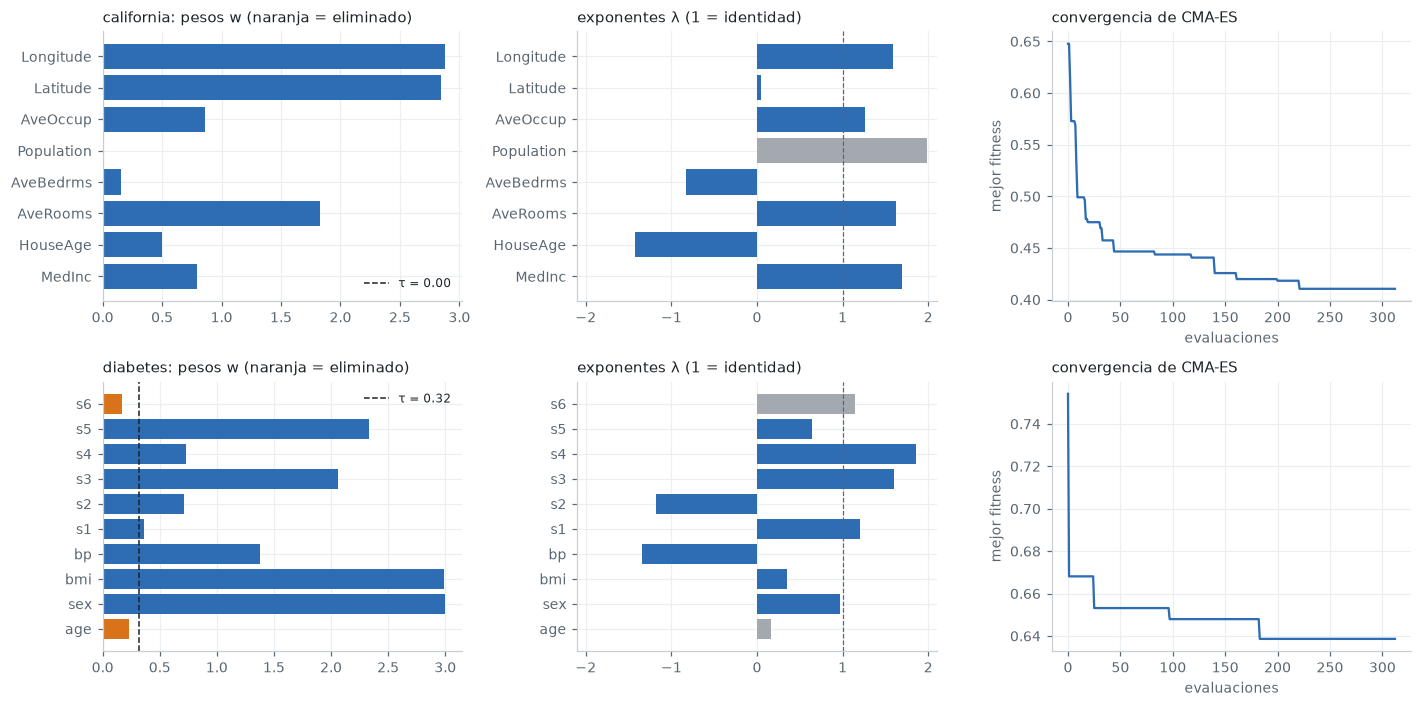

In [4]:
fig, ejes = plt.subplots(2, 3, figsize=(13, 6.5))
for i, (nombre, (P, Xt, *_)) in enumerate(demo.items()):
    cols = pd.read_csv(os.path.join(metodo.RAIZ, metodo.PRACTICA[nombre][0])).columns.drop(metodo.PRACTICA[nombre][1])
    fuera = ~np.isin(np.arange(len(cols)), P.S)
    ejes[i, 0].barh(cols, P.w, color=np.where(fuera, A.NARANJA, A.AZUL))
    ejes[i, 0].axvline(P.tau, color=A.TINTA, ls="--", lw=1, label=f"τ = {P.tau:.2f}")
    ejes[i, 0].set_title(f"{nombre}: pesos w (naranja = eliminado)", loc="left"); ejes[i, 0].legend(fontsize=8)
    ejes[i, 1].barh(cols, P.lam, color=np.where(fuera, A.GRIS, A.AZUL)); ejes[i, 1].axvline(1, color=A.TINTA2, ls="--", lw=0.8)
    ejes[i, 1].set_xlim(-2.1, 2.1); ejes[i, 1].set_title("exponentes λ (1 = identidad)", loc="left")
    ejes[i, 2].plot(P.curva, color=A.AZUL); ejes[i, 2].set_title("convergencia de CMA-ES", loc="left")
    ejes[i, 2].set_xlabel("evaluaciones"); ejes[i, 2].set_ylabel("mejor fitness")
fig.tight_layout(); plt.show()

Los atributos en naranja son los que la búsqueda ha decidido eliminar: su peso quedó por debajo del umbral $\tau$ que **ella misma** ha aprendido. En la curva de convergencia, el primer valor es el fitness de la estandarización quitando un atributo (por la restricción $s<n$).

## 4. Protocolo experimental

- **Datos.** 12 datasets de regresión: los 2 de la práctica y 10 de OpenML (6–12 atributos numéricos, como mucho 10 000 filas).
- **Particiones de confirmación.** Las variantes del método se exploraron con otras semillas. Los resultados que siguen usan particiones 70/30 **nuevas** (semillas 40–44). El valor de $\alpha=0$ (sin penalización por dimensión) se fijó *antes* de mirar los resultados, por no añadir hiperparámetros.
- **Modelos triviales y fijos.** Regresión lineal, KNN ($k=5$), árbol de decisión y Random Forest (100 árboles), con los parámetros por defecto. El enunciado fija el modelo $M$: ajustar sus hiperparámetros sería cambiar el modelo, no los datos.
- **Estadística por dataset.** Las particiones de un mismo dataset comparten filas, así que no son independientes. La unidad es el **dataset** ($n=12$): cada uno se resume con la media geométrica de $e'/e$ en sus particiones. Pares: **Wilcoxon** con corrección de **Holm**; comparaciones múltiples: **Friedman** con la diferencia crítica de **Nemenyi** (Demšar, 2006).

## 5. Ejecución de los experimentos

Cada celda repite un experimento solo si su entrada de `RECALCULAR` es `True`; si no, se usa el CSV guardado. El orden importa: `comparativa` y `cribado` reutilizan los $\theta$ aprendidos en `final`.

In [5]:
def ejecutar(clave, carpeta, script, csv, args=(), env_extra=None):
    ruta_csv = os.path.join(carpeta, "resultados", csv)
    if not RECALCULAR.get(clave, False):
        estado = "guardado" if os.path.exists(ruta_csv) else "NO EXISTE: pon RECALCULAR['%s'] = True" % clave
        print(f"[{clave}] se usa el CSV {estado}: {os.path.relpath(ruta_csv, RAIZ)}")
        return
    if os.path.exists(ruta_csv) and not clave.startswith("busqueda") and not clave == "reduccion":
        shutil.copy(ruta_csv, ruta_csv + ".bak"); os.remove(ruta_csv)     # se repite desde cero
    env = dict(os.environ, N_JOBS=str(N_JOBS), **(env_extra or {}))
    t0 = time.time()
    print(f"[{clave}] ejecutando {script} {' '.join(args)} ...", flush=True)
    r = subprocess.run([sys.executable, script, *args], cwd=carpeta, env=env, capture_output=True, text=True)
    print(r.stdout[-1500:], r.stderr[-1500:] if r.returncode else "")
    print(f"[{clave}] terminado en {(time.time()-t0)/60:.1f} min (código {r.returncode})")

ejecutar("final", FINAL, "experimento_final.py", "final.csv")
ejecutar("reduccion", REDUC, "experimento_reduccion.py", "reduccion.csv", env_extra={"VARIANTES": "τ+ρ α=0,τ α=0"})
ejecutar("cribado", REDUC, "cribado_posthoc.py", "cribado_posthoc.csv")
ejecutar("comparativa", FINAL, "experimento_comparativa.py", "comparativa.csv")
for bloque in ["controles", "rango", "algoritmos", "inicio"]:
    ejecutar("busqueda_" + bloque, FINAL, "experimento_busqueda.py", "busqueda.csv", args=(bloque,))
ejecutar("parada", FINAL, "experimento_parada.py", "parada.csv")

[final] se usa el CSV guardado: final/resultados/final.csv
[reduccion] se usa el CSV guardado: reduccion/resultados/reduccion.csv
[cribado] se usa el CSV guardado: reduccion/resultados/cribado_posthoc.csv
[comparativa] se usa el CSV guardado: final/resultados/comparativa.csv
[busqueda_controles] se usa el CSV guardado: final/resultados/busqueda.csv
[busqueda_rango] se usa el CSV guardado: final/resultados/busqueda.csv
[busqueda_algoritmos] se usa el CSV guardado: final/resultados/busqueda.csv
[busqueda_inicio] se usa el CSV guardado: final/resultados/busqueda.csv
[parada] se usa el CSV guardado: final/resultados/parada.csv


> Nota: `experimento_busqueda.py` y `experimento_reduccion.py` **añaden** filas a su CSV y se saltan las particiones ya hechas (se pueden interrumpir y reanudar). Para repetirlos desde cero, borra antes su CSV o las filas del bloque.

## 6. Análisis completo

`analisis.py` es la única fuente de números y figuras: regenera `figuras/`, `numeros.tex` y `tablas.tex` (que usan la memoria, el paper y el póster).

In [6]:
cifras = A.todas()
d = A.cargar_final()
print(len(cifras), "cifras exportadas a numeros.tex;", d.dataset.nunique(), "datasets ×", d.semilla.nunique(), "particiones")

227 cifras exportadas a numeros.tex; 12 datasets × 5 particiones


## 7. ¿Se cumple $e' < e$ con menos atributos?

$P$ (con reducción) frente a $X$ original, a $X$ estandarizado y al $P$ anterior sin reducir ($2n$ atributos).

In [7]:
t = A.tabla_principal(d)
t[["estandar", "sin_reducir", "cociente_orig", "ds_mejora_orig", "casos_mejora_orig", "p_orig", "p_holm_orig",
   "cambio_est", "p_holm_est"]].rename(columns={
    "estandar": "estándar", "sin_reducir": "P sin reducir (2n)", "cociente_orig": "P (e'/e)", "ds_mejora_orig": "datasets e'<e",
    "casos_mejora_orig": "casos e'<e", "p_orig": "p", "p_holm_orig": "p Holm", "cambio_est": "% vs estándar",
    "p_holm_est": "p Holm vs estándar"}).round(4)

,estándar,P sin reducir (2n),P (e'/e),datasets e'<e,casos e'<e,p,p Holm,% vs estándar,p Holm vs estándar
modelo,,,,,,,,,
Regresión lineal,0.982,0.940,0.957,7,36,4.238e-01,1.000,-2.618,1.000
KNN,0.876,0.750,0.757,12,56,5.000e-04,0.004,-13.563,0.048
Árbol,1.000,0.988,1.001,7,34,7.910e-01,1.000,0.112,1.000
Random Forest,1.000,0.978,1.005,5,27,5.186e-01,1.000,0.506,1.000


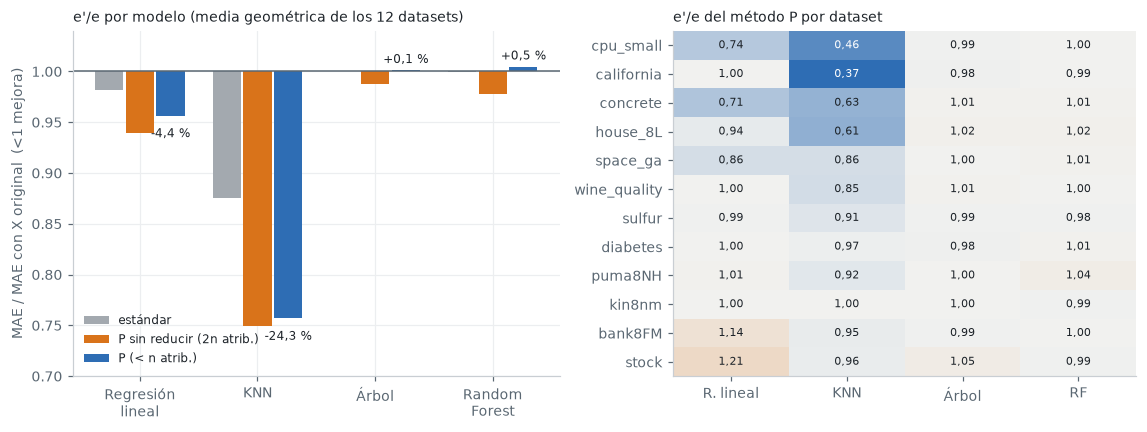

In [8]:
A.fig_principal(d); plt.show()

- **KNN**: mejora grande y concluyente con menos atributos (−24,3 %, 12/12 datasets, $p_{Holm}=0{,}004$), también frente a estandarizar (−13,6 %, $p_{Holm}=0{,}048$). Casi igual que sin reducir (−25 %).
- **Regresión lineal**: −4,4 % en media (7/12 datasets), no significativo. Empeora en stock (+21 %) y bank8FM (+14 %).
- **Árbol y Random Forest**: el error queda igual (+0,1 % y +0,5 %). **$e'<e$ solo se cumple en media para KNN y la regresión lineal.**

## 8. La reducción de dimensionalidad

### Cuántos atributos elimina la evolución
Por dataset (media de las 5 particiones): $n$ atributos originales, $s$ que se quedan, $m$ componentes sintetizadas, $\dim X'$ y el umbral $\tau$ aprendido (mediana).

In [9]:
td = A.tabla_dimension(d)
display(td.round(2))
u = d[d.representacion == "P"].drop_duplicates(["dataset", "semilla"])
print(f"dim X'/n medio: {(u.dim/u.n_atributos).mean():.2f}  ·  atributos originales eliminados: {(1-u.s/u.n_atributos).mean():.0%}"
      f"  ·  particiones con síntesis (m>0): {(u.m>0).mean():.0%}  ·  τ mediano: {u.tau.median():.2f}")
print("dim X' < n en todas las particiones:", bool((u.dim < u.n_atributos).all()))

,n,s,m,dim,tau,rho,dim/n
dataset,,,,,,,
diabetes,10,8.0,0.6,8.6,0.46,0.50,0.86
concrete_compressive_strength,8,6.6,0.0,6.6,0.47,0.14,0.82
stock,9,7.6,0.4,8.0,0.30,0.64,0.89
space_ga,6,3.8,0.4,4.2,0.09,0.56,0.70
sulfur,6,5.0,0.0,5.0,0.01,0.44,0.83
wine_quality,11,9.6,0.2,9.8,0.41,0.32,0.89
kin8nm,8,7.0,0.0,7.0,0.34,0.67,0.88
bank8FM,8,6.8,0.2,7.0,0.05,0.79,0.88
puma8NH,8,2.2,2.4,4.6,1.83,0.51,0.57


dim X'/n medio: 0.83  ·  atributos originales eliminados: 22%  ·  particiones con síntesis (m>0): 25%  ·  τ mediano: 0.18
dim X' < n en todas las particiones: True


### Qué cuesta reducir y qué aporta la síntesis
- **Coste de reducir**: $P$ ($<n$ atributos) frente a $P$ sin reducir ($2n$).
- **Aporte de la síntesis**: $P$ (reducción + síntesis) frente a $P$ solo con reducción ($\rho$ eliminado del genoma).

In [10]:
display(Markdown("**P frente a P sin reducir** (< 1: reducir mejora)"))
display(A.efecto_reduccion(d)[["cociente", "ds_mejora", "ds", "p", "p_holm"]].round(4))
display(Markdown("**P frente a P solo con reducción** (< 1: la síntesis ayuda)"))
display(A.efecto_sintesis(d)[["cociente", "ds_mejora", "ds", "p", "p_holm"]].round(4))

**P frente a P sin reducir** (< 1: reducir mejora)

,cociente,ds_mejora,ds,p,p_holm
modelo,,,,,
Regresión lineal,1.018,5,12,0.380,0.380
KNN,1.010,4,12,0.110,0.330
Árbol,1.014,3,12,0.110,0.330
Random Forest,1.028,1,12,0.012,0.049


**P frente a P solo con reducción** (< 1: la síntesis ayuda)

,cociente,ds_mejora,ds,p,p_holm
modelo,,,,,
Regresión lineal,0.987,7,12,0.204,0.705
KNN,0.997,7,12,0.176,0.705
Árbol,1.003,7,12,0.970,1.000
Random Forest,0.999,7,12,0.569,1.000


- **Cuánto reduce**: $X'$ usa el 83 % de los atributos de media (entre el 38 % y el 92 % según la partición) y nunca $n$. La evolución elimina uno o dos atributos en casi todos los datasets; en **puma8NH** (donde pocos atributos explican $y$) se queda con 2 de 8 y añade componentes.
- **Qué cuesta**: frente a $P$ sin reducir, KNN +1,0 %, regresión lineal +1,8 % y árbol +1,4 %, sin significación; **Random Forest +2,8 % ($p_{Holm}=0{,}049$)**, porque pierde las $n$ direcciones oblicuas de la síntesis completa.
- **Qué aporta la síntesis** dentro del presupuesto: casi nada. CMA-ES solo sintetiza en el 25 % de las particiones, y quitar $\rho$ cambia el error menos de un 1,5 %. Con un fitness de KNN, la búsqueda prefiere conservar atributos originales a añadir componentes.

### Contraste: ¿y si el umbral se fija fuera de la evolución?
`reduccion/cribado_posthoc.py` reutiliza los $\theta$ de $P$ sin reducir y aplica después una regla fija: quitar atributos por peso creciente y quedarse con el menor $s<n$ cuyo fitness no supera el mejor + 1 error estándar (regla 1-SE, Breiman et al., 1984). También prueba un umbral fijo $w<0{,}1$ y "solo PCA" truncada con la misma regla.

In [11]:
cr = pd.read_csv(os.path.join(REDUC, "resultados", "cribado_posthoc.csv"))
p = cr.pivot_table(index=["dataset", "semilla", "modelo"], columns="representacion", values="mae")
rel = np.log(p.div(p["original"], axis=0))
reps = ["estándar", "P", "sel w<0.1", "sel τ*", "pca q*", "sel τ* + pca"]
g = np.exp(rel.groupby("modelo")[reps].mean()); g.loc["MEDIA"] = np.exp(rel[reps].mean())
dim = cr.drop_duplicates(["dataset", "semilla", "representacion"]).assign(f=lambda x: x.dim / x.n).groupby("representacion").f.mean()
g.loc["dim/n"] = dim[reps]
display(g.rename(columns={"P": "P sin reducir (2n)"}).round(3))
print("sel w<0.1 no reduce (s = n) en", int((cr[cr.representacion == "sel w<0.1"].drop_duplicates(["dataset", "semilla"]).eval("dim == n")).sum()), "de 60 particiones")

representacion,estándar,P sin reducir (2n),sel w<0.1,sel τ*,pca q*,sel τ* + pca
modelo,,,,,,
KNN,0.876,0.750,0.750,0.761,0.761,0.764
Random Forest,1.000,0.977,1.000,1.008,1.019,1.006
Regresión lineal,0.982,0.939,0.946,0.975,0.973,0.975
Árbol,1.000,0.989,0.995,1.001,1.008,0.995
MEDIA,0.963,0.908,0.917,0.930,0.934,0.929
dim/n,1.000,2.000,0.889,0.723,0.697,0.867


sel w<0.1 no reduce (s = n) en 27 de 60 particiones


Fijar el umbral **fuera** de la evolución con la regla 1-SE da un resultado parecido al de $P$ (KNN −23,9 %, con el 72 % de los atributos), pero es una regla externa añadida después. Un umbral fijo $w_j<0{,}1$ **no reduce nada en 27 de 60 particiones**, así que no cumple el enunciado. Aprender $\tau$ dentro de la búsqueda garantiza $s<n$ sin reglas externas.

## 9. Comparativa con otras transformaciones

`experimento_comparativa.py` compara, en las mismas particiones: estandarizar; Yeo-Johnson por máxima verosimilitud; cuantiles; "solo PCA" (95 % de varianza o % elegido por validación cruzada); añadir la PCA de $X$ estandarizado; **MLKR** (aprendizaje de métricas para regresión); y **programación genética** (`gplearn`). La última columna es la dimensión media de $X'$ relativa a $n$.

In [12]:
c = A.cargar_comparativa()
tc, n = A.tabla_comparativa(c)
print(n, "particiones con todas las transformaciones; p: Wilcoxon por dataset de P frente a cada una, con Holm")
tc[A.MODELOS + ["rango medio", "dim/n"] + ["p " + m for m in A.MODELOS]].round(3)

60 particiones con todas las transformaciones; p: Wilcoxon por dataset de P frente a cada una, con Holm


,Regresión lineal,KNN,Árbol,Random Forest,rango medio,dim/n,p Regresión lineal,p KNN,p Árbol,p Random Forest
estándar,0.982,0.876,1.000,1.000,5.344,1.000,1.000,0.041,1.000,1.000
YJ máx. verosimilitud,1.024,0.855,1.015,1.017,5.042,1.000,1.000,0.049,1.000,1.000
cuantiles,1.081,0.882,1.001,1.000,6.396,1.000,0.617,0.022,1.000,1.000
PCA 95 %,1.006,0.896,1.193,1.179,8.052,0.794,1.000,0.027,0.009,0.031
PCA v-CV,0.990,0.880,1.187,1.151,7.385,0.905,1.000,0.027,0.020,0.188
estándar + PCA,0.982,0.876,0.994,0.981,4.552,2.000,1.000,0.041,1.000,0.554
MLKR,0.982,0.775,1.020,1.026,5.740,1.000,1.000,0.233,1.000,1.000
PG (gplearn),0.843,0.820,1.007,1.008,4.594,2.000,0.083,0.049,1.000,1.000
P sin reducir,0.939,0.750,0.989,0.977,3.188,2.000,1.000,0.220,1.000,0.098
P,0.956,0.757,1.001,1.005,4.708,0.828,NaN,NaN,NaN,NaN


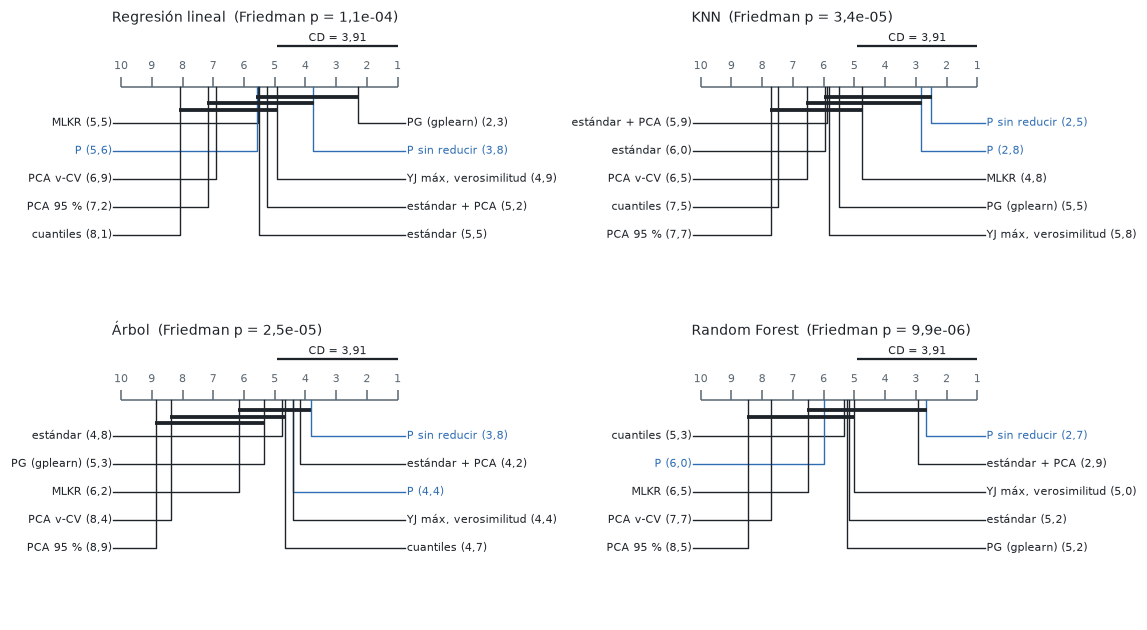

In [13]:
A.fig_comparativa_cd(c); plt.show()

- Las tres transformaciones con mejor rango medio (**$P$ sin reducir**, estándar + su PCA y programación genética) usan **$2n$ atributos**.
- **Entre las que no aumentan la dimensión, $P$ es la mejor** (rango 4,7 frente a 5,0 de Yeo-Johnson por máxima verosimilitud) y la única que reduce sin dañar a los árboles.
- En KNN, $P$ supera a todas salvo a MLKR y a $P$ sin reducir (sin diferencia significativa). En regresión lineal gana la programación genética (0,84), porque construir atributos no lineales es justo lo que necesita un modelo lineal.
- **"Solo PCA"**, la otra forma de reducir, empeora mucho a los árboles (+15–19 %).

## 10. La síntesis en árboles

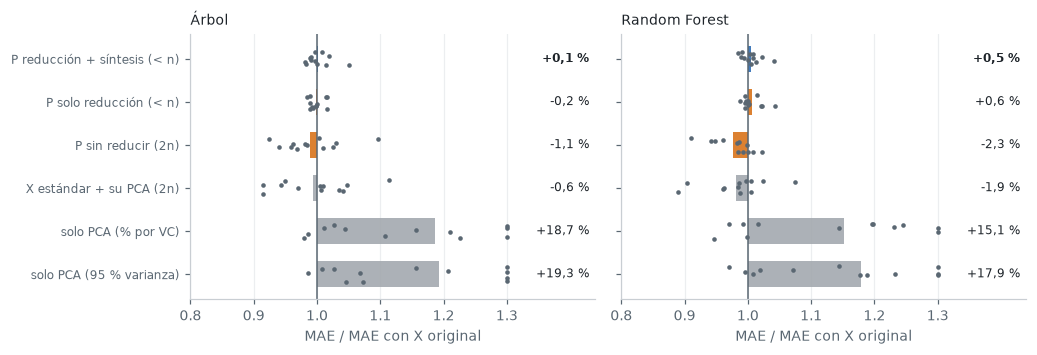

In [14]:
A.fig_sintesis(c); plt.show()

A Random Forest le ayuda **añadir** direcciones oblicuas a los ejes originales ($P$ sin reducir −2,3 %; $X$ estándar + su PCA −1,9 %), lo que exige $\dim X' > n$. **Sustituir** los ejes por componentes ("solo PCA") lo empeora un 15–18 %. Con $\dim X'<n$, $P$ (reducción + síntesis) y $P$ solo con reducción quedan en +0,5 %: no empeoran a RF, pero ya no lo mejoran. Esta es la tensión central entre reducir y sintetizar.

## 11. La búsqueda: piezas, población inicial, rango y algoritmo

`experimento_busqueda.py` repite la búsqueda de $(\lambda, w)$ cambiando una sola decisión cada vez (particiones 40–41, mismo fitness y presupuesto). La referencia es CMA-ES con $m_0=\theta_0$, $\sigma_0=0{,}2$, población por defecto y $\lambda\in[-2,2]$ (el $P$ sin reducir). Estas decisiones son las mismas en el $P$ final, que solo añade $\tau$ y $\rho$ al genoma. Cociente > 1: peor que la referencia.

In [15]:
b = A.cargar_busqueda()
variantes = [v for _, v, _ in A.ABLACION if v in set(b.variante)]
A.contra_referencia(b, variantes).round(4)

,casos,KNN,p KNN,ds peor KNN,Regresión lineal,p Regresión lineal,ds peor Regresión lineal,Random Forest,p Random Forest,ds peor Random Forest,p_holm KNN,p_holm Regresión lineal,p_holm Random Forest
variante,,,,,,,,,,,,,
solo pesos,24,1.022,0.424,7,1.065,0.077,9,0.999,0.622,4,1.000,0.849,1.000
solo exponentes,24,1.100,0.003,11,1.022,0.110,8,1.004,0.424,3,0.034,0.989,1.000
pesos MI,24,1.149,0.002,10,1.068,0.034,10,1.036,0.151,8,0.029,0.410,1.000
YJ máx. verosimilitud + pesos MI,24,1.110,0.007,9,1.103,0.339,7,1.036,0.064,9,0.061,1.000,0.704
búsqueda aleatoria,24,1.062,0.002,11,1.030,0.129,7,1.020,0.007,11,0.029,1.000,0.082
inicio aleatorio,24,1.006,0.850,5,1.017,0.519,7,1.006,0.970,6,1.000,1.000,1.000
sigma0=0.1,24,1.005,0.791,6,0.999,0.677,8,1.008,0.233,8,1.000,1.000,1.000
sigma0=0.4,24,1.009,0.677,6,0.996,0.733,6,1.006,0.569,6,1.000,1.000,1.000
población x2,24,1.002,0.970,6,0.998,0.970,7,1.013,0.470,7,1.000,1.000,1.000


- **Piezas.** Los pesos son la pieza principal: fijar $w=1$ empeora a KNN un 10 % (significativo). Quitar Yeo-Johnson cuesta un 2 % en KNN y un 6,5 % en la regresión lineal, sin significación con 12 datasets. En el $P$ final los pesos tienen además un segundo papel: deciden qué atributos se eliminan.
- **Búsqueda.** La búsqueda aleatoria con el mismo presupuesto es un 6 % peor en KNN (significativo), y asignar los pesos por información mutua, sin búsqueda, un 15 %.
- **Población inicial.** CMA-ES es robusto a cómo empieza; mantenemos $m_0=\theta_0$ (estandarizar) porque arranca en la línea base y hace la búsqueda reproducible e interpretable.

### Operadores evolutivos

| | CMA-ES (método) | AG propio (contraste) |
|---|---|---|
| Individuo | $\theta$ real en $[0,1]^{2n+2}$, reescalado a los límites | igual |
| Población inicial | distribución $\mathcal N(\theta_0, 0{,}2^2 I)$ | $\theta_0$ + 29 puntos uniformes |
| Tamaño | $\lambda = 4+\lfloor 3\ln D\rfloor$ | 30 |
| Selección | truncamiento por **rango**: los $\mu=\lambda/2$ mejores, con pesos decrecientes | torneo de 3 |
| Recombinación | intermedia ponderada de los $\mu$ seleccionados (nueva media) | BLX-$\alpha$ ($\alpha=0{,}3$) |
| Mutación | muestreo de $\mathcal N(m,\sigma^2C)$; $\sigma$ y $C$ adaptativas | gaussiana, $p=1/D$ |
| Reemplazo | $(\mu/\mu_w,\lambda)$ generacional, no elitista; se guarda el mejor evaluado | generacional + elitismo 1 |
| Restricciones | transformación al cubo $[0,1]^D$; **$s<n$ por decodificación** | recorte |
| Parada | 1000 evaluaciones | 1000 evaluaciones |

,casos,KNN,p KNN,ds peor KNN,p_holm KNN
R = 0,24,1.022,0.424,7,1.000
R = 1,24,1.003,0.850,6,1.000
R = 4,24,1.005,0.970,7,1.000
R = 8,24,1.017,0.064,9,0.256


fracción de λ en el borde: {1: 0.108, 2: 0.072, 4: 0.083, 8: 0.054}


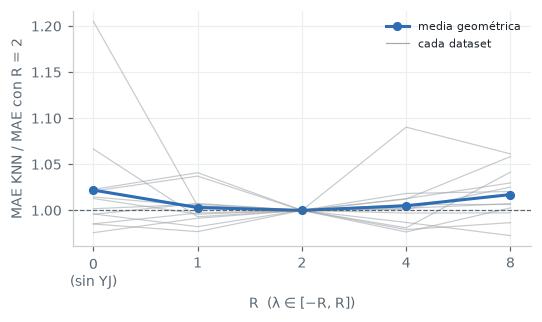

24 particiones comunes


,rango,fitness,cambio KNN,cambio Regresión lineal
variante,,,,
CMA-ES,1.875,0.438,-25.655,-7.732
AG (propio),2.792,0.440,-24.450,-8.527
HS,3.250,0.443,-24.463,-8.323
BBO,4.417,0.445,-24.815,-7.950
PSO,4.458,0.445,-24.100,-5.126
DE,5.417,0.450,-23.330,-5.937
ABC,5.875,0.452,-23.966,-2.359
búsqueda aleatoria,7.917,0.466,-21.036,-4.919


,dataset,D,lambda_pob,mu,mu_eff,generaciones,evaluaciones,parada,eval_mejor,fitness_inicial,fitness_final,sigma_final
0,diabetes,20,12,6,3.729,84,1008,maxfevals,658,0.690,0.631,0.048
1,california,16,12,6,3.729,84,1008,maxfevals,1005,0.509,0.383,0.064
2,concrete_compressive_strength,16,12,6,3.729,84,1008,maxfevals,952,0.524,0.311,0.052
3,stock,18,12,6,3.729,84,1008,maxfevals,969,0.110,0.095,0.034
4,space_ga,12,11,5,3.415,91,1001,maxfevals,998,0.584,0.533,0.031
5,sulfur,12,11,5,3.415,91,1001,maxfevals,892,0.483,0.443,0.023
6,kin8nm,16,12,6,3.729,84,1008,maxfevals,1005,0.505,0.454,0.007
7,bank8FM,16,12,6,3.729,84,1008,maxfevals,683,0.373,0.201,0.032
8,puma8NH,16,12,6,3.729,84,1008,maxfevals,1001,0.671,0.536,0.035
9,house_8L,16,12,6,3.729,84,1008,maxfevals,945,0.634,0.562,0.034


In [16]:
tr, borde = A.tabla_rango(b)
display(tr.round(4)); print("fracción de λ en el borde:", {R: round(v, 3) for R, v in borde.items()})
A.fig_rango(b, figsize=(5, 3)); plt.show()
ta, n = A.tabla_algoritmos(b)
print(n, "particiones comunes"); display(ta.round(3))
pd.read_csv("resultados/parada.csv")[["dataset", "D", "lambda_pob", "mu", "mu_eff", "generaciones", "evaluaciones",
                                      "parada", "eval_mejor", "fitness_inicial", "fitness_final", "sigma_final"]].round(3)

Con el mismo $\theta$, fitness y presupuesto, CMA-ES obtiene el mejor rango de fitness, pero el AG, HS y BBO quedan cerca y solo la búsqueda aleatoria es claramente peor: **la búsqueda importa; el algoritmo concreto, bastante menos**. Las búsquedas se detienen por presupuesto con el mejor $\theta$ casi al final.

## 12. Coste y caso negativo

,mediana,maximo
metodo,,
"P (CMA-ES, 1000 evaluaciones)",190.56,242.65
MLKR,16.81,41.84
PG (gplearn),6.11,14.08
PCA v-CV,1.05,11.51
YJ máx. verosimilitud,0.59,4.30
cuantiles,0.08,0.80
estándar + PCA,0.01,0.02


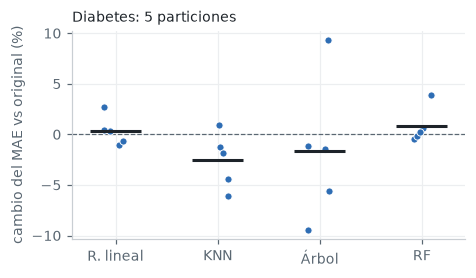

In [17]:
display(A.tabla_coste(c).round(2))
A.fig_diabetes(d); plt.show()

Una búsqueda de $P$ tarda ~3 minutos por partición con 20 procesos (1000 evaluaciones de una validación cruzada de KNN sobre ≤ 2000 filas; un poco más que sin reducir, porque cada evaluación calcula una PCA). Se paga una sola vez por dataset; aplicar la transformación es inmediato y, al tener $X'$ menos columnas, los modelos se entrenan más rápido. En **diabetes** (309 filas de entrenamiento) la búsqueda mejora el fitness pero no la validación de forma fiable: sobreajuste al criterio de búsqueda con pliegues de ~60 filas.

## 13. Conclusiones

1. **$P$ cumple las dos exigencias del enunciado**: $\dim X'<n$ en todas las particiones (83 % de los atributos de media), con el criterio de eliminación ($\tau$) aprendido por CMA-ES, y síntesis de componentes cuando el fitness la elige.
2. **$e'<e$ en media para KNN** (−24,3 %, concluyente) **y la regresión lineal** (−4,4 %, no significativo). En los árboles el error queda igual.
3. **Reducir y sintetizar compiten.** A los árboles les ayuda *añadir* direcciones oblicuas, lo que exige aumentar la dimensión. Con $\dim X'<n$ y un fitness de KNN, la evolución prefiere quedarse con los atributos originales. Reducir cuesta poco, salvo en Random Forest (+2,8 %).
4. **Entre las transformaciones que no aumentan la dimensión, $P$ tiene el mejor rango medio**; las que la superan usan $2n$ atributos.
5. **Las decisiones de la búsqueda están contrastadas**: los pesos son la pieza clave (y ahora deciden también qué se elimina); la búsqueda gana al azar y a los filtros; el algoritmo, la población inicial y el rango de $\lambda$ influyen poco.
6. **Límites**: 12 datasets numéricos y pequeños; sobreajuste con pocos datos (diabetes); el fitness optimiza KNN, así que el reparto del presupuesto de atributos no tiene en cuenta a los árboles. Un fitness que combine varias familias de modelos es el siguiente paso natural.

In [18]:
# Recompilar los documentos (opcional; requiere una distribución de LaTeX con latexmk)
if COMPILAR_LATEX:
    subprocess.run(["pdflatex", "-interaction=nonstopmode", "esquema.tex"], cwd=os.path.join(FINAL, "figuras"))
    for carpeta, tex in [("memoria", "memoria.tex"), ("paper", "paper.tex"), ("poster", "poster.tex")]:
        r = subprocess.run(["latexmk", "-pdf", "-interaction=nonstopmode", tex], cwd=os.path.join(FINAL, carpeta),
                           capture_output=True, text=True)
        print(carpeta, "OK" if r.returncode == 0 else "ERROR")